In [1]:
!pip install pandas numpy scikit-learn xgboost matplotlib joblib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, json, joblib, sklearn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from xgboost import XGBClassifier

DATA_PATH = "Telco-Customer-Churn-data.csv"  
TARGET = "Churn"
DROP_COLS = ["customerID"]
SEED = 42
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks -> NaN
print(df.shape); print(df[TARGET].value_counts()); print(df.isna().sum()[df.isna().sum() > 0])

df = df.drop(columns=DROP_COLS).dropna(subset=[TARGET]).drop_duplicates()
X = df.drop(columns=[TARGET])
le = LabelEncoder()
y = pd.Series(le.fit_transform(df[TARGET]), index=df.index)
n_classes = len(le.classes_)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print("num:", num_cols); print("cat:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

(7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64
TotalCharges    11
dtype: int64
num: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
cat: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"f1": "f1", "roc_auc": "roc_auc"}

def make(model):
    return Pipeline([("prep", preprocess), ("model", model)])

models = {
    "random_guess": make(DummyClassifier(strategy="stratified", random_state=SEED)),
    "logreg_baseline": make(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "rf_baseline": make(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)),
}
results = {}
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results[name] = {"cv_f1": s["test_f1"].mean(), "cv_roc_auc": s["test_roc_auc"].mean()}
pd.DataFrame(results).T

,cv_f1,cv_roc_auc
random_guess,0.269266,0.502336
logreg_baseline,0.629492,0.845820
rf_baseline,0.543679,0.824832


In [4]:
xgb = make(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1))
search = RandomizedSearchCV(
    xgb,
    {"model__n_estimators": [200, 400, 600], "model__max_depth": [3, 4, 6, 8],
     "model__learning_rate": [0.01, 0.05, 0.1], "model__subsample": [0.7, 0.9, 1.0],
     "model__colsample_bytree": [0.7, 0.9, 1.0]},
    n_iter=15, cv=cv, scoring="f1", random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
best = search.best_estimator_
results["xgb_tuned"] = {"cv_f1": search.best_score_, "best_params": search.best_params_}
print(results["xgb_tuned"])

version = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = f"models/pipeline_xgb_v{version}.joblib"
joblib.dump({"pipeline": best, "label_encoder": le}, model_path)
json.dump({"version": version, "sklearn": sklearn.__version__, "target": TARGET,
           "features": X.columns.tolist(), "cv_results": results},
          open(f"models/pipeline_xgb_v{version}.json", "w"), indent=2, default=str)
print("Saved:", model_path)

{'cv_f1': np.float64(0.5929657083792942), 'best_params': {'model__subsample': 0.7, 'model__n_estimators': 600, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.9}}
Saved: models/pipeline_xgb_v20261107_162457.joblib


              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.49      0.56       372

    accuracy                           0.79      1405
   macro avg       0.73      0.70      0.71      1405
weighted avg       0.78      0.79      0.78      1405

F1=0.5559  ROC-AUC=0.8396  AP=0.6474


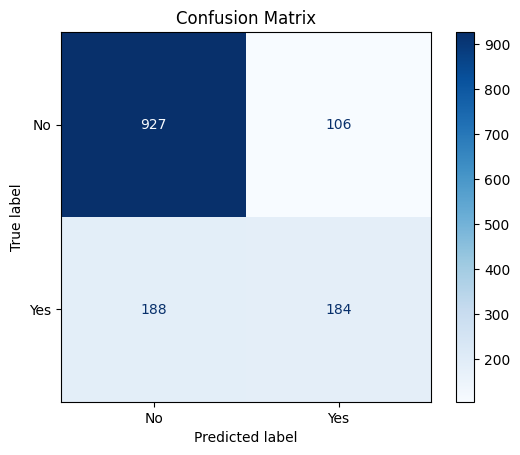

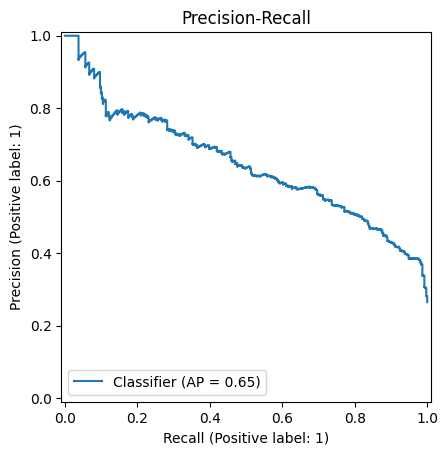

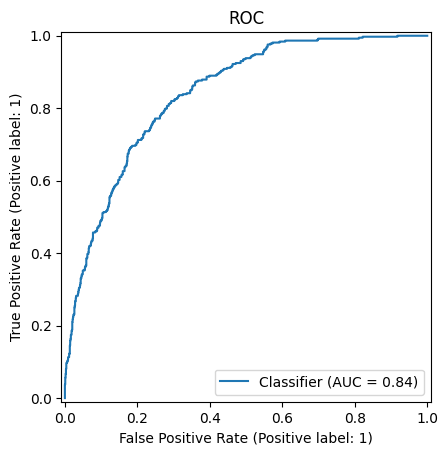

In [5]:
y_pred = best.predict(X_test)
proba = best.predict_proba(X_test)
report = classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_])
print(report)
f1 = f1_score(y_test, y_pred); auc = roc_auc_score(y_test, proba[:, 1]); ap = average_precision_score(y_test, proba[:, 1])
print(f"F1={f1:.4f}  ROC-AUC={auc:.4f}  AP={ap:.4f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap="Blues")
plt.title("Confusion Matrix"); plt.savefig("outputs/confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

PrecisionRecallDisplay.from_predictions(y_test, proba[:, 1]); plt.title("Precision-Recall")
plt.savefig("outputs/pr_curve.png", dpi=150, bbox_inches="tight"); plt.show()

RocCurveDisplay.from_predictions(y_test, proba[:, 1]); plt.title("ROC")
plt.savefig("outputs/roc_curve.png", dpi=150, bbox_inches="tight"); plt.show()

In [6]:
err = X_test.copy()
err["y_true"] = le.inverse_transform(y_test)
err["y_pred"] = le.inverse_transform(y_pred)
err["confidence"] = proba.max(axis=1)
err = err[err["y_true"] != err["y_pred"]].sort_values("confidence", ascending=False)
err.head(20).to_csv("outputs/misclassified_top20.csv")
print("Total misclassified:", len(err))
err.head(20)

Total misclassified: 294


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,y_true,y_pred,confidence
4272,Male,0,Yes,No,56,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.15,1327.15,Yes,No,0.990317
6724,Female,1,No,No,64,Yes,No,DSL,Yes,Yes,...,Yes,No,Two year,Yes,Credit card (automatic),70.20,4481.00,Yes,No,0.984292
1780,Female,0,No,Yes,18,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,One year,No,Bank transfer (automatic),20.15,390.85,Yes,No,0.983819
4539,Male,0,Yes,Yes,67,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Two year,Yes,Electronic check,79.70,5293.40,Yes,No,0.969163
4698,Female,1,Yes,No,66,Yes,Yes,DSL,No,Yes,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),80.55,5265.10,Yes,No,0.968521
4149,Male,0,Yes,No,71,No,No phone service,DSL,No,Yes,...,Yes,Yes,Two year,No,Electronic check,49.35,3515.25,Yes,No,0.941945
2529,Male,1,No,No,45,Yes,No,DSL,Yes,No,...,No,Yes,One year,No,Credit card (automatic),62.70,2791.50,Yes,No,0.938713
3528,Male,0,No,No,16,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.70,342.40,Yes,No,0.931647
4910,Female,0,No,No,30,Yes,No,DSL,Yes,Yes,...,Yes,Yes,One year,No,Bank transfer (automatic),85.35,2530.40,Yes,No,0.930492
6762,Male,0,No,No,35,Yes,No,DSL,No,No,...,Yes,No,Month-to-month,No,Mailed check,55.00,2010.55,Yes,No,0.928364


In [7]:
err["type"] = np.where(err["y_true"] == "Yes", "missed churn (FN)", "false alarm (FP)")
print(err["type"].value_counts())
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print("\n", col); print(err[col].value_counts())
print("\ntenure (misclassified) vs all test:")
print(err["tenure"].describe()[["mean", "50%"]]); print(X_test["tenure"].describe()[["mean", "50%"]])

type
missed churn (FN)    188
false alarm (FP)     106
Name: count, dtype: int64

 Contract
Contract
Month-to-month    252
One year           34
Two year            8
Name: count, dtype: int64

 InternetService
InternetService
Fiber optic    165
DSL            101
No              28
Name: count, dtype: int64

 PaymentMethod
PaymentMethod
Electronic check             148
Mailed check                  54
Bank transfer (automatic)     50
Credit card (automatic)       42
Name: count, dtype: int64

tenure (misclassified) vs all test:
mean    20.639456
50%     14.500000
Name: tenure, dtype: float64
mean    32.614235
50%     30.000000
Name: tenure, dtype: float64


In [8]:
print(df.groupby("Contract")["Churn"].apply(lambda s: (s=="Yes").mean()).round(3))
print(df.groupby("InternetService")["Churn"].apply(lambda s: (s=="Yes").mean()).round(3))

top = err.head(20)
print(top["type"].value_counts())
print(top["Contract"].value_counts())
print(top["InternetService"].value_counts())
print(top[["tenure","MonthlyCharges"]].describe().loc[["mean","min","max"]])

t = X_test.copy(); t["y"] = y_test; t["pred"] = y_pred
t["tenure_bin"] = pd.cut(t["tenure"], [-1,12,24,48,72])
print(t[t.y==1].groupby("tenure_bin", observed=True).apply(lambda g: (g.pred==1).mean()).round(3))

Contract
Month-to-month    0.426
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
InternetService
DSL            0.189
Fiber optic    0.418
No             0.072
Name: Churn, dtype: float64
type
missed churn (FN)    20
Name: count, dtype: int64
Contract
Two year          7
One year          7
Month-to-month    6
Name: count, dtype: int64
InternetService
DSL            10
No              8
Fiber optic     2
Name: count, dtype: int64
      tenure  MonthlyCharges
mean   34.25          50.815
min     2.00          19.700
max    71.00         113.150
tenure_bin
(-1, 12]    0.657
(12, 24]    0.431
(24, 48]    0.288
(48, 72]    0.029
dtype: float64


In [9]:
# ---- evidence compute ----
err["type"] = np.where(err["y_true"] == "Yes", "missed churn (FN)", "false alarm (FP)")
top = err.head(20)
n_err = len(err)
fn = int((err["type"] == "missed churn (FN)").sum()); fp = int((err["type"] == "false alarm (FP)").sum())

# Failure mode 1: confident missed churn
fn_df = err[err["y_true"] == "Yes"]
top_contract = top["Contract"].value_counts().to_dict()
top_internet = top["InternetService"].value_counts().to_dict()
top_fn = int((top["type"] == "missed churn (FN)").sum())
top_conf_min, top_conf_max = top["confidence"].min(), top["confidence"].max()
fn_long = int((fn_df["Contract"] != "Month-to-month").sum())

# Failure mode 2: month-to-month / short tenure
t = X_test.copy(); t["y"] = y_test; t["pred"] = y_pred
m = t[t["Contract"] == "Month-to-month"]
m2m_err = int((err["Contract"] == "Month-to-month").sum())
m2m_churn_rate = (df[df["Contract"] == "Month-to-month"]["Churn"] == "Yes").mean()
m2m_recall = ((m.pred == 1) & (m.y == 1)).sum() / (m.y == 1).sum()
m2m_prec = ((m.pred == 1) & (m.y == 1)).sum() / max((m.pred == 1).sum(), 1)
tenure_err, tenure_all = err["tenure"].mean(), X_test["tenure"].mean()
contract_churn = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).round(3).to_dict()

report_md = f"""# Model Evaluation & Error Analysis (Telco Customer Churn)

**Model:** XGBoost (tuned), version {version}
**Test metrics:** F1={f1:.3f}, ROC-AUC={auc:.3f}, Average Precision={ap:.3f}
**Baselines (5-fold CV F1):** random guess={results['random_guess']['cv_f1']:.3f}, LogReg={results['logreg_baseline']['cv_f1']:.3f}, RandomForest={results['rf_baseline']['cv_f1']:.3f}, XGBoost tuned={results['xgb_tuned']['cv_f1']:.3f}

The tuned model beats the random-guess baseline by a wide margin, but recall for the churn class is low: the model misses about half of the real churners.

## Overall error picture
- Test set has {len(y_test)} customers, model made {n_err} errors: **{fn} missed churn (FN)** and **{fp} false alarms (FP)**.
- Most errors are missed churners ({fn/n_err:.0%}), so the model is conservative: it tends to say "No churn".
- Reviewed the 20 most confident errors (`misclassified_top20.csv`): {top_fn} of 20 are missed churners, predicted "No" with confidence between {top_conf_min:.2f} and {top_conf_max:.2f}.

## Failure Mode 1: Confident misses on customers who look loyal
- **What we saw:** In the top-20 confident errors the contract split is {top_contract} and internet service split is {top_internet}. Many of these customers have long tenure, a one/two-year contract, automatic payment, or no internet service (low bill ~ $20), yet they churned. Overall, {fn_long} of {fn} missed churners are NOT on a month-to-month contract.
- **Hypothesis:** The model learned that long contract + high tenure + auto-pay means "stays". These customers fit that pattern, so it is very confident, but their real reason for leaving (competitor offer, moving, price, service issue) is not captured in the available columns. The "no internet" segment also has a low base churn rate, so the model treats the whole segment as safe and cannot isolate its few churners.
- **Data-level fix:** Add features that capture the trigger for leaving: support calls / complaints, drop in usage, days to contract renewal, failed payments, recent plan or price change. Collect more labelled churn examples from the low-churn segments so the model sees them.

## Failure Mode 2: Month-to-month and short-tenure customers are hard to separate
- **What we saw:** {m2m_err} of {n_err} errors ({m2m_err/n_err:.0%}) are month-to-month customers. Churn rate by contract is {contract_churn}. Among month-to-month customers in the test set the model reaches recall={m2m_recall:.2f} and precision={m2m_prec:.2f}. Misclassified customers have a mean tenure of {tenure_err:.1f} months vs {tenure_all:.1f} for the whole test set, so errors concentrate on newer customers.
- **Hypothesis:** Month-to-month is a high-risk but mixed group: a large share churn and a large share stay. Inside it, the available features (contract, tenure, charges, services) look similar for both outcomes, so the model cannot draw a clean boundary and makes both FP and FN errors. New customers also have little history, so their behaviour is noisy.
- **Data-level fix:** Add behavioural history features (usage trend in first months, onboarding/promotion end date, number of service changes), tenure buckets, `MonthlyCharges/tenure`, and services-count. Gather more data for early-tenure customers.

## Class imbalance and threshold
- Churn is about 27% of the data and the default 0.5 threshold favours the majority class, which explains recall of only {fn_df.shape[0] and (1 - fn/(fn + int(((t.y==1)&(t.pred==1)).sum()))):.2f}.
- Fix: class weights / `scale_pos_weight`, resampling (e.g. SMOTE) only inside the training folds, and a lower decision threshold chosen on validation or CV data, not on the test set.

## Proposed data-level fixes (summary)
1. Add behavioural and event features (support calls, usage trend, renewal date, payment failures).
2. Add engineered features: tenure buckets, services count, charges per month of tenure.
3. Collect more labelled examples for new customers and for low-churn segments (long contract, no internet).
4. Handle imbalance in training only (class weights / SMOTE inside CV) and tune the threshold on validation data.
5. Re-check labels and features for the confident errors for possible data quality issues.
"""

with open("outputs/report.md", "w", encoding="utf-8") as f:
    f.write(report_md)
print(report_md)

# Model Evaluation & Error Analysis (Telco Customer Churn)

**Model:** XGBoost (tuned), version 20261107_162457
**Test metrics:** F1=0.556, ROC-AUC=0.840, Average Precision=0.647
**Baselines (5-fold CV F1):** random guess=0.269, LogReg=0.629, RandomForest=0.544, XGBoost tuned=0.593

The tuned model beats the random-guess baseline by a wide margin, but recall for the churn class is low: the model misses about half of the real churners.

## Overall error picture
- Test set has 1405 customers, model made 294 errors: **188 missed churn (FN)** and **106 false alarms (FP)**.
- Most errors are missed churners (64%), so the model is conservative: it tends to say "No churn".
- Reviewed the 20 most confident errors (`misclassified_top20.csv`): 20 of 20 are missed churners, predicted "No" with confidence between 0.91 and 0.99.

## Failure Mode 1: Confident misses on customers who look loyal
- **What we saw:** In the top-20 confident errors the contract split is {'Two year': 7, 'One year': 7, 'Mon

In [2]:
import shutil
shutil.make_archive("outputs_bundle", "zip", "outputs")
shutil.make_archive("models_bundle", "zip", "models")
print("done")

done
